In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)


In [3]:
# 3.1 Деректерді жүктеу
df = pd.read_csv('data.csv')
print(df.head())
print(df.info())

   text_length  num_links  num_exclamations  num_uppercase_words  \
0          185          1                 3                    0   
1          179          0                 1                    0   
2          171          1                 1                    1   
3          190          0                 0                    0   
4          185          0                 0                    0   

   spam_word_count  has_currency  is_reply  sender_in_contacts  \
0                2             1         0                   0   
1                0             0         0                   1   
2                5             1         0                   0   
3                0             0         1                   1   
4                0             0         0                   1   

   has_attachment  hour_sent  result  
0               0          8       1  
1               0         14       0  
2               0         12       1  
3               0         18       0  

In [4]:
# 3.2 Алдын ала талдау
print(df.describe())
print(df.isnull().sum())
print('Қайталанатын жазбалар:', df.duplicated().sum())
print(df['result'].value_counts())


       text_length   num_links  num_exclamations  num_uppercase_words  \
count   300.000000  300.000000        300.000000            300.00000   
mean    177.406667    0.366667          1.343333              0.31000   
std      27.682649    0.482700          1.667751              0.62332   
min     112.000000    0.000000          0.000000              0.00000   
25%     161.000000    0.000000          0.000000              0.00000   
50%     180.000000    0.000000          1.000000              0.00000   
75%     189.000000    1.000000          1.000000              0.00000   
max     256.000000    1.000000          6.000000              3.00000   

       spam_word_count  has_currency    is_reply  sender_in_contacts  \
count       300.000000    300.000000  300.000000          300.000000   
mean          1.256667      0.363333    0.193333            0.450000   
std           1.943376      0.481763    0.395572            0.498325   
min           0.000000      0.000000    0.000000      

In [5]:
# 3.3 Белгілер мен мақсатты айнымалы
features = ['text_length', 'num_links', 'num_exclamations', 'num_uppercase_words',
            'spam_word_count', 'has_currency', 'is_reply', 'sender_in_contacts',
            'has_attachment', 'hour_sent']
X = df[features]
y = df['result']


In [6]:
# 3.4 Бөлу және масштабтау
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [7]:
# 3.5 Модель
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)


LogisticRegression(max_iter=1000, random_state=42)

In [8]:
# 3.6 Болжам
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]
print('Болжанған кластар:', y_pred)
print('1-класс (спам) ықтималдықтары:', y_prob.round(3))


Болжанған кластар: [0 0 0 0 0 0 1 0 1 0 1 1 0 1 1 1 1 0 1 1 0 0 1 0 1 0 0 1 0 1 0 1 1 0 0 1 0
 1 1 1 0 1 1 1 0 0 1 0 1 1 0 1 0 0 1 1 0 0 0 1]
1-класс (спам) ықтималдықтары: [0.005 0.001 0.006 0.009 0.001 0.018 1.    0.021 0.999 0.007 1.    0.999
 0.001 1.    0.998 0.701 1.    0.001 1.    1.    0.005 0.005 0.975 0.454
 0.995 0.006 0.008 0.94  0.013 0.998 0.009 0.998 0.995 0.006 0.009 1.
 0.01  1.    0.997 0.926 0.003 0.999 0.998 0.999 0.304 0.007 0.888 0.008
 0.994 0.645 0.021 0.71  0.014 0.352 0.999 0.716 0.039 0.02  0.018 0.935]


In [9]:
# 3.7 Сапаны бағалау
print('Accuracy:', accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))


Accuracy: 0.9666666666666667
              precision    recall  f1-score   support

           0       0.97      0.97      0.97        30
           1       0.97      0.97      0.97        30

    accuracy                           0.97        60
   macro avg       0.97      0.97      0.97        60
weighted avg       0.97      0.97      0.97        60



[[29  1]
 [ 1 29]]


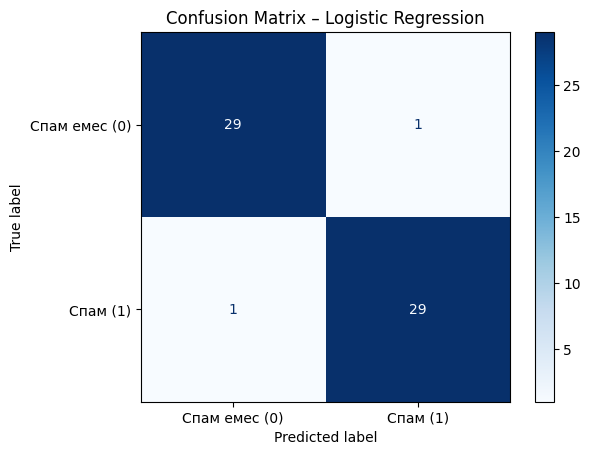

In [11]:
# 3.8 Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Спам емес (0)', 'Спам (1)'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix – Logistic Regression')
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

In [10]:
# Коэффициенттер (қосымша талдау үшін)
print(pd.Series(model.coef_[0], index=features).sort_values())


sender_in_contacts    -2.128850
is_reply              -0.810508
text_length           -0.761718
num_exclamations      -0.672956
hour_sent             -0.302530
has_attachment        -0.068964
num_uppercase_words    1.119752
has_currency           1.510946
num_links              1.568485
spam_word_count        1.888366
dtype: float64


In [12]:
# 3.9 Жаңа хат үшін болжам
new_email = pd.DataFrame([[210, 1, 3, 4, 5, 1, 0, 0, 0, 3]], columns=features)
new_scaled = scaler.transform(new_email)
prediction = model.predict(new_scaled)
probability = model.predict_proba(new_scaled)
print('Болжамды класс:', prediction[0])
print('Кластар ықтималдығы [0, 1]:', probability[0])


Болжамды класс: 1
Кластар ықтималдығы [0, 1]: [9.90328550e-08 9.99999901e-01]
